# Part 1 — baselines and feature experiments

This notebook presents representative algorithms and feature choices from the report. It **freshly reruns the original validation comparisons** for the historical GMM-assisted model, then reads compact records for the separate K-means/DBSCAN and feature-screen studies. It does not rerun every grid setting.

**Historical boundary:** the first model below predates anchored. Its unsupervised scaler/PCA/GMM and feature transforms see unlabeled validation/test inputs; its pseudo-label pool includes test inputs. Validation labels stay outside fitting. This is an explicitly historical, transductive comparison, not the strict-inductive winning model and not our current grouped benchmark. The original notebook is preserved in `resources/legacy_feature_model.ipynb`.

The code is adapted from that notebook only to use packaged paths and to run validation without its expensive historical CV loop. Notebook 05 contains the full original source. The older CV averages and current grouped CV must not be mixed.
Run with Python 3.12 and the pinned `requirements.txt` beside this notebook. In Colab, extract the complete ZIP, change into `midterm/part1`, and install those dependencies before running. The supplied inputs and selected evidence are included; no Git checkout, private path, external trial data, or model cache is required. Notebook 05 contains the complete packaged Python source.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

# Works from the extracted part1 directory or from the repository root.
options = [Path.cwd(), Path.cwd() / "submission/midterm/part1", Path.cwd() / "midterm/part1"]
HOME = next((p for p in options if (p / "resources/handin.py").is_file()), None)
if HOME is None:
    raise RuntimeError("Extract the complete Part 1 ZIP and open this notebook beside its resources folder.")
RES = HOME / "resources"
OUT = HOME / "generated"
OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(RES))
import handin as h
P1, LABELS, EMB = h.P1, h.LABELS, h.EMB
# Stable numerical behavior; release automatically when the kernel exits.
thread_limit = threadpool_limits(limits=1)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
display(h.verify_resources())

{'files': 763, 'hashes_match': True, 'external_checkout_required': False}

## Historical preprocessing and model definitions

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.mixture import GaussianMixture
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import KFold
from sklearn.metrics import f1_score
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator

RDLogger.DisableLog('rdApp.*')
SEED = 0
DATA = str(P1 / "data") + "/"
LABELS = ['Safety', 'Funding', 'Efficacy', 'Recruitment', 'Other']
EMB = [f'emb_{i}' for i in range(150)]

train = pd.read_csv(DATA + 'part1_train.csv')
val = pd.read_csv(DATA + 'part1_val.csv')
test = pd.read_csv(DATA + 'part1_test.csv')
is_lab = (train[LABELS] != -100).all(axis=1).values

print(f'train {train.shape}, labeled {is_lab.sum()}, unlabeled {(~is_lab).sum()} | val {val.shape} | test {test.shape}')
pd.DataFrame({'labeled train': train.loc[is_lab, LABELS].mean(), 'val': val[LABELS].mean()}).T.round(3)

train (1171, 166), labeled 157, unlabeled 1014 | val (78, 166) | test (312, 161)


,Safety,Funding,Efficacy,Recruitment,Other
labeled train,0.102,0.051,0.108,0.643,0.159
val,0.115,0.051,0.179,0.641,0.128


In [3]:
n_tr, n_va, n_te = len(train), len(val), len(test)
emb_all = np.vstack([train[EMB].values, val[EMB].values, test[EMB].values])
X_all = StandardScaler().fit_transform(emb_all)
X_tr, X_va, X_te = X_all[:n_tr], X_all[n_tr:n_tr + n_va], X_all[n_tr + n_va:]
Y_tr, Y_va = train[LABELS].values, val[LABELS].values

pca30 = PCA(30, random_state=SEED).fit(X_all)
gmm = GaussianMixture(30, covariance_type='diag', n_init=3, random_state=SEED).fit(pca30.transform(X_all))
print('GMM converged:', gmm.converged_, '| iterations:', gmm.n_iter_, '| tol:', gmm.tol)

GMM converged: True | iterations: 30 | tol: 0.001


/Users/michael/Documents/School/Cornell/AppliedMachineLearning/.venv/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:134: UserWarning: Could not find the number of physical cores for the following reason:
invalid literal for int() with base 10: ''
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/Users/michael/Documents/School/Cornell/AppliedMachineLearning/.venv/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/michael/Documents/School/Cornell/AppliedMachineLearning/.venv/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 420, in _count_physical_cores_darwin
    return int(cpu_info)
           ^^^^^^^^^^^^^


In [4]:
def decide(P, thr=0.3):
    Y = (P >= thr).astype(int)
    Y[np.arange(len(P)), P.argmax(1)] = 1
    return Y


def expand(X, Y, w):
    rows, ys, ws = [], [], []
    for i, y in enumerate(Y):
        pos = np.flatnonzero(y)
        rows += [i] * len(pos); ys += list(pos); ws += [w[i] / len(pos)] * len(pos)
    return X[rows], np.array(ys), np.array(ws)


def multinomial_lr(Xl, Yl, Xq, C=0.3, balanced=True):
    X, y, sw = expand(Xl, Yl, np.ones(len(Yl)))
    if balanced:
        cnt = np.bincount(y, weights=sw, minlength=5) + 1e-9
        sw = sw * cnt.mean() / cnt[y]
    m = LogisticRegression(C=C, max_iter=3000).fit(X, y, sample_weight=sw)
    P = np.zeros((len(Xq), 5))
    P[:, m.classes_] = m.predict_proba(Xq)
    return P


def knn(Xl, Yl, Xq, k=10):
    S = normalize(Xq) @ normalize(Xl).T
    idx = np.argsort(-S, 1)[:, :k]
    w = np.take_along_axis(S, idx, 1).clip(0) ** 2
    T = Yl / Yl.sum(1, keepdims=True)
    return (w[:, :, None] * T[idx]).sum(1) / (w.sum(1, keepdims=True) + 1e-9)


def gmm_cluster_label(Xl, Yl, Xq, a=1.0):
    Rl, Rq = (gmm.predict_proba(pca30.transform(M[:, :len(EMB)])) for M in (Xl, Xq))
    T = Yl / Yl.sum(1, keepdims=True)
    cluster_dist = (Rl.T @ T + a * T.mean(0)) / (Rl.sum(0)[:, None] + a)
    return Rq @ cluster_dist


def base_model(Xl, Yl, Xq, w_knn=0.3):
    return (1 - w_knn) * multinomial_lr(Xl, Yl, Xq) + w_knn * knn(Xl, Yl, Xq)


def final_model(Xl, Yl, Xq, Xu, w_gmm=0.2, conf=0.8, thr=0.3, rounds=2, return_aug=False):
    XL, YL = Xl, Yl
    for _ in range(rounds):
        Pu = (1 - w_gmm) * base_model(XL, YL, Xu) + w_gmm * gmm_cluster_label(XL, YL, Xu)
        keep = Pu.max(1) >= conf
        XL, YL = np.vstack([Xl, Xu[keep]]), np.vstack([Yl, decide(Pu, thr)[keep]])
    P = base_model(XL, YL, Xq)
    return (P, keep.sum()) if return_aug else P

In [5]:
X_pool, Y_pool = np.vstack([X_tr[is_lab], X_va]), np.vstack([Y_tr[is_lab], Y_va])
X_unl = np.vstack([X_tr[~is_lab], X_te])
def validation_result(name, fn, Xl=X_tr[is_lab], Xq=X_va, Xu=X_unl):
    score = fn(Xl, Y_tr[is_lab], Xq, Xu)
    metric, _ = h.metrics(Y_va, decide(score))
    return {"model": name, **metric}

In [6]:
def ovr_lr(Xl, Yl, Xq, C=1.0):
    return np.column_stack([LogisticRegression(C=C, max_iter=2000).fit(Xl, Yl[:, j]).predict_proba(Xq)[:, 1]
                            for j in range(5)])


candidates = {
    'One-vs-rest LR (C=1)': lambda a, b, c, u: ovr_lr(a, b, c),
    'kNN cosine (k=10)': lambda a, b, c, u: knn(a, b, c),
    'GMM-30 cluster-then-label': lambda a, b, c, u: gmm_cluster_label(a, b, c),
    'Multinomial LR, unbalanced': lambda a, b, c, u: multinomial_lr(a, b, c, balanced=False),
    'Balanced multinomial LR + kNN': lambda a, b, c, u: base_model(a, b, c),
    'Self-training, no GMM': lambda a, b, c, u: final_model(a, b, c, u, w_gmm=0.0),
    'FINAL: GMM-assisted self-training': final_model,
}

## Representative classifier and self-training comparisons

These are fresh validation fits with the historical access boundary stated above. Every row shares that boundary. The label-only GMM is weak; adding supervised scores and conservative self-training improved this earlier model. The table does not imply that these values belong to the final anchored model.

In [7]:
comparison = pd.DataFrame([validation_result(name, fn) for name, fn in candidates.items()])
display(comparison)
comparison.to_csv(OUT / "historical_baselines_validation.csv", index=False)
expected = [.868, .872, .780, .850, .885, .889, .893]
np.testing.assert_allclose(comparison.sample_f1, expected, atol=.00051, rtol=0)

,model,sample_f1,macro_f1
0,One-vs-rest LR (C=1),0.867521,0.706410
1,kNN cosine (k=10),0.871795,0.607493
2,GMM-30 cluster-then-label,0.779915,0.570290
3,"Multinomial LR, unbalanced",0.850427,0.676825
4,Balanced multinomial LR + kNN,0.884615,0.724006
5,"Self-training, no GMM",0.888889,0.722948
6,FINAL: GMM-assisted self-training,0.893162,0.713700


## Feature ablations from the report

Add each block separately to the same earlier model: start year; eligibility TF-IDF reduced to 50 SVD coordinates; disease TF-IDF reduced to 20; and 1,024-bit Morgan fingerprints reduced to 20. Missing/unmatched drugs receive zero fingerprints; multiple matched drugs use the elementwise maximum. Feature transforms below retain the historical transductive boundary for an exact comparison.

This experiment supports the narrower claim that these encodings did not improve this model's validation score. It does not prove those fields cannot help other models.

In [8]:
def svd_block(M, k):
    return StandardScaler().fit_transform(TruncatedSVD(k, random_state=SEED).fit_transform(M))


def text_col(col):
    return pd.concat([train[col], val[col], test[col]]).fillna('').astype(str).values


fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)


def trial_fingerprint(smiles):
    if not isinstance(smiles, str):
        return np.zeros(1024)
    fps = [fp_gen.GetFingerprintAsNumPy(m) for s in smiles.split(';') if (m := Chem.MolFromSmiles(s)) is not None]
    return np.max(fps, axis=0) if fps else np.zeros(1024)


year = pd.concat([train.start_year, val.start_year, test.start_year]).values.astype(float)
extra = {
    '+ start_year': ((year - year.mean()) / year.std())[:, None],
    '+ criteria TF-IDF (SVD 50)': svd_block(TfidfVectorizer(min_df=3, ngram_range=(1, 2), sublinear_tf=True,
                                                           max_features=20000).fit_transform(text_col('criteria')), 50),
    '+ diseases TF-IDF (SVD 20)': svd_block(TfidfVectorizer(min_df=2).fit_transform(text_col('diseases_cleaned')), 20),
    '+ Morgan fingerprints (SVD 20)': svd_block(np.vstack([trial_fingerprint(s) for s in text_col('drug_smiles')
                                                           .astype(object)]).astype(float), 20),
}


def split_feats(F):
    return F[:n_tr], F[n_tr:n_tr + n_va], F[n_tr + n_va:]

,model,sample_f1,macro_f1
0,embeddings only,0.893162,0.713700
1,+ start_year,0.891026,0.711394
2,+ criteria TF-IDF (SVD 50),0.876068,0.709213
3,+ diseases TF-IDF (SVD 20),0.876068,0.696228
4,+ Morgan fingerprints (SVD 20),0.888889,0.718924


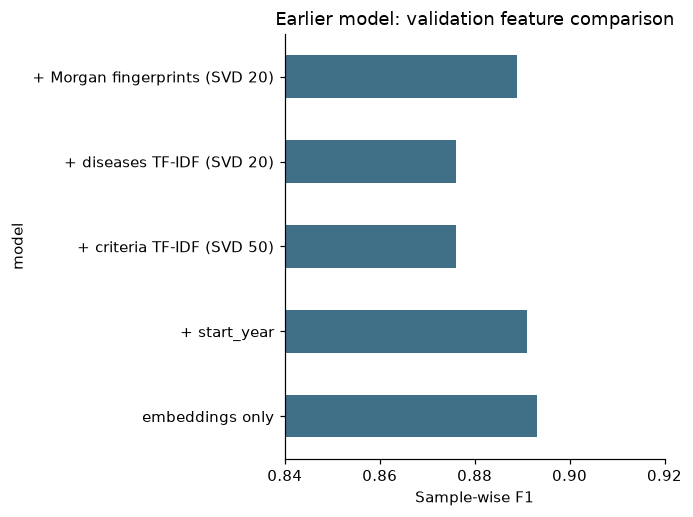

In [9]:
rows = [validation_result("embeddings only", final_model)]
for name, block in extra.items():
    a, b, c = split_feats(np.hstack([X_all, block]))
    rows.append(validation_result(name, final_model, Xl=a[is_lab], Xq=b, Xu=np.vstack([a[~is_lab], c])))
ablation = pd.DataFrame(rows)
display(ablation)
np.testing.assert_allclose(ablation.sample_f1, [.893,.891,.876,.876,.889], atol=.00051, rtol=0)
ablation.to_csv(OUT / "historical_feature_validation.csv", index=False)
ax = ablation.set_index("model").sample_f1.plot.barh(color="#407088", title="Earlier model: validation feature comparison")
ax.set_xlim(.84,.92); ax.set_xlabel("Sample-wise F1"); plt.tight_layout()
plt.savefig(OUT / "feature_comparison.png"); plt.show()

### What the feature comparison suggests

The embedding-only historical model reached sample-wise F1 **0.89316**. Adding year reduced it to **0.89103**, criteria or disease text to **0.87607**, and Morgan fingerprints to **0.88889**. The fingerprints slightly improved macro F1 (**0.71892** versus **0.71370**) while reducing the selection metric, so the trade-off depends on how labels are weighted.

Our hypothesis is that stopping-reason embeddings already capture the most direct signal, while the extra representations add noise and dimensionality to only 157 labeled training examples. Drug matching is incomplete, and trial descriptors need not explain why a trial stopped. This ablation tests each block separately; it does not establish that every combined representation or another model would fail. We retained embeddings for the winning model and used stronger grouped/chronological checks for later comparisons.


## Separate clustering and feature-screen families

The following tables are **retained historical search results**, not fresh fits in this cell. They include K-means, diagonal/tied GMM, DBSCAN, graph labeling, nonlinear classifiers, pathways, drug targets/actions and missingness indicators. Their thresholds, pseudo-label weighting and parents differ from the model above, so compare within each study. The original notebook source, fixed settings and complete compact result tables are packaged; omitted fitted estimators and generated matrices are not needed by these finalized notebooks.

In [10]:
clustering = pd.read_csv(P1 / "experiments/method_comparison/clustering_comparison.csv")
display(clustering.loc[clustering.groupby("family").sample_f1.idxmax(), ["family","k","generated_trials","sample_f1","macro_f1"]])
classical = pd.read_csv(P1 / "experiments/additional_methods/new_comparison.csv")
display(classical.sort_values("sample_f1", ascending=False).head(8))
for folder in ["classifier_features", "remaining_classifier_features"]:
    filename = "comparison.csv" if folder == "classifier_features" else "best_by_group.csv"
    table = pd.read_csv(P1 / "experiments" / folder / filename)
    print(folder, "— retained study table")
    display(table[[c for c in ["experiment","feature_group","sample_f1","macro_f1","delta_vs_current_leader"] if c in table]])

,family,k,generated_trials,sample_f1,macro_f1
5,gmm_diag,2,0,0.893162,0.804324
13,gmm_tied,10,696,0.905983,0.811626
2,kmeans,8,803,0.901709,0.809077


,experiment,category,classifier,dataset,parameters,generated_trials,unlabeled_trials_used,sample_f1,macro_f1,fallback_trials,...,min_samples,clusters,noise_trials,neighbors,alpha,graph_components,training_reason_slots_without_label_mass,maximum_iterations_used,validation_reason_slots_using_supervised_fallback,delta_vs_dbscan_lr
24,dbscan_m5_q25__logistic_C1000,label_generation,logistic,dbscan_m5_q25,"{""C"": 1000.0}",133.0,133,0.910256,0.811421,4,...,5.0,18.0,878.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
27,dbscan_m10_q25__logistic_C1000,label_generation,logistic,dbscan_m10_q25,"{""C"": 1000.0}",188.0,188,0.897436,0.803884,4,...,10.0,9.0,874.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
29,dbscan_m10_q75__logistic_C1000,label_generation,logistic,dbscan_m10_q75,"{""C"": 1000.0}",0.0,0,0.893162,0.804324,4,...,10.0,1.0,149.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26,dbscan_m5_q75__logistic_C1000,label_generation,logistic,dbscan_m5_q75,"{""C"": 1000.0}",0.0,0,0.893162,0.804324,4,...,5.0,2.0,207.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28,dbscan_m10_q50__logistic_C1000,label_generation,logistic,dbscan_m10_q50,"{""C"": 1000.0}",526.0,526,0.893162,0.798706,8,...,10.0,4.0,493.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
42,hybrid_gmm_dbscan__logistic_C1000,hybrid_label_generation,logistic,hybrid_gmm_dbscan,"{""C"": 1000.0, ""label_sources"": {""Efficacy"": ""d...",704.0,704,0.888889,0.793668,4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25,dbscan_m5_q50__logistic_C1000,label_generation,logistic,dbscan_m5_q50,"{""C"": 1000.0}",483.0,483,0.888889,0.789590,7,...,5.0,9.0,526.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16,frozen_gmm_tied_k10__rbf_svm_C10p0_gammascale,supervised_comparison,rbf_svm,frozen_gmm_tied_k10,"{""C"": 10.0, ""gamma"": ""scale""}",696.0,696,0.867521,0.720646,13,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


classifier_features — retained study table


,experiment,feature_group,sample_f1,macro_f1
0,embeddings_only,none,0.910256,0.811421
1,diseases_min2,diseases,0.910256,0.811421
2,diseases_min3,diseases,0.910256,0.811421
3,diseases_min5,diseases,0.910256,0.811421
4,pathway_missing_only,missing_only,0.905983,0.805106
5,pathways_min1,pathways,0.873932,0.760207
6,pathways_min5,pathways,0.873932,0.760207
7,pathways_min30,pathways,0.873932,0.760207
8,criteria_min3,criteria,0.910256,0.811421
9,criteria_min50,criteria,0.897436,0.801106


remaining_classifier_features — retained study table


,experiment,feature_group,sample_f1,macro_f1,delta_vs_current_leader
0,embeddings_only_C1000,none,0.910256,0.811421,0.000000
1,matched_drugs_min5_C1000,matched_drugs,0.910256,0.811421,0.000000
2,drug_actions_missing_only_C1000,missing_only,0.905983,0.805106,-0.004274
3,drug_targets_min5_C1000,drug_targets,0.901709,0.803884,-0.008547
4,drugs_min5_C1000,drugs,0.897436,0.803884,-0.012821
5,icdcodes_min5_C1000,icdcodes,0.895299,0.800687,-0.014957
6,drug_actions_min5_C100,drug_actions,0.888889,0.800905,-0.021368
7,smiles_C1000,smiles,0.884615,0.783190,-0.025641
8,year_C100,year,0.826923,0.710959,-0.083333


## Why this did not select the final winner

The DBSCAN/logistic recipe reached .910256 on the original validation set, but the original157 and final235 submissions scored .87500 and .86452. That difference does not isolate a cause of refit degradation. More extensive feature sweeps also reused the same 78 labels, so their best values are development results. The stronger grouped and chronological comparisons in notebook 03 were introduced to make those limitations visible. Current-model boundary handling must be read from notebook 01, not inferred from these older studies.